# Figure: Literature Review Amery & Prydz Bay

## Load Modules

In [1]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import matplotlib.ticker as mticker
from matplotlib import path
from matplotlib.colors import TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.patches import Polygon, Rectangle
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import geopandas as gpd
import pandas as pd

import xarray as xr
from netCDF4 import Dataset
from xgcm import Grid
import cmaps
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import glob

import rioxarray

from dask.diagnostics import ProgressBar

from scipy.ndimage import gaussian_filter1d

from pyproj import Transformer

import seawater as sw
import gsw

import calendar

import pickle

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/sitecustomize.py:72: UserWarning: The seawater library is deprecated! Please use gsw instead.
  mod = _real_import(name, globals, locals, fromlist, level)


## Import

In [2]:
# ---------- LIMA ----------
lima_full = rioxarray.open_rasterio('/g/data/jk72/deg581/apom/ana/data/raw/lima/00000-20080319-092059124.tif')
lima = lima_full.where((lima_full.x>1.65e6)&(lima_full.x<2.5e6)&(lima_full.y>.4e6)&(lima_full.y<1e6),drop=True)

# ---------- Melt Map ----------
melt_map_full = rioxarray.open_rasterio('/g/data/gv90/ad6790/amery-amisor/data/external/melt_rate/Adusumilli2020_Melt.tif')
melt_map = melt_map_full.where((melt_map_full.x>1.65e6)&(melt_map_full.x<2.5e6)&(melt_map_full.y>.4e6)&(melt_map_full.y<1e6),drop=True)

# ---------- Quantarctica ----------
# Already in EPSG3031

# --- MEaSUREs Antarctic Boundaries ---
coastline = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/Coastline_Antarctica_v2.shp')
grounding_line = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/GroundingLine_Antarctica_v2.shp')
ice_boundaries = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/IceBoundaries_Antarctica_v2.shp')

float_ice = ice_boundaries[ice_boundaries['TYPE'] == 'FL'].dissolve()
land = ice_boundaries[ice_boundaries['TYPE'].isin(['GR', 'IS'])].dissolve()

# --- BEDMAP2 (Ice Thickness, Bed & Surface Elevation) ---
thickness = rioxarray.open_rasterio('/g/data/jk72/jl0818/DATA/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_thickness.tif').squeeze()
bed = rioxarray.open_rasterio('/g/data/jk72/jl0818/DATA/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_bed.tif').squeeze()
surface = rioxarray.open_rasterio('/g/data/jk72/jl0818/DATA/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_surface.tif').squeeze()

# --- LAT/LON GRATICULES ---
lat_1dg = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Miscellaneous/Graticules/1dg_latitude.shp')
lat_2dg = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Miscellaneous/Graticules/2dg_latitude.shp')
lon_2dg = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Miscellaneous/Graticules/2dg_longitude.shp')
lon_5dg = gpd.read_file('/g/data/jk72/jl0818/DATA/Quantarctica3/Miscellaneous/Graticules/5dg_longitude.shp')

# --- PRYDZ BAY FEATURES ---
polynyas = gpd.read_file('/g/data/gv90/ad6790/amery-amisor/data/external/Polynyas_Portela_2021.shp')
pbg = gpd.read_file('/g/data/gv90/ad6790/amery-amisor/data/external/Prydz Bay Gyre.shp')
fast_ice = gpd.read_file('/g/data/gv90/ad6790/amery-amisor/data/external/Pyrdz Bay_Fast Ice_Portela_2021.shp')
asc = gpd.read_file('/g/data/gv90/ad6790/amery-amisor/data/external/ASC.shp')
pbecc = gpd.read_file('/g/data/gv90/ad6790/amery-amisor/data/external/PBECC.shp')

## Find AMISOR Borehole Locations

In [3]:
# Initialise a dictionary to hold information on the physical boreholes
# Borehole lon/lats are at deployment (most change across recording period by less than ~2 km, and maximum ~5 km) 
# Index 0 is coordinates (lon, lat)
boreholes_amisor = {
    'AM01': {'lonlat': (71.417083, -69.442033)},
    'AM02': {'lonlat': (72.639983, -69.713767)},
    'AM03': {'lonlat': (70.332167, -70.561167)},
    'AM04': {'lonlat': (70.290333, -69.8995)},
    'AM05': {'lonlat': (69.675, -70.231667)},
    'AM06': {'lonlat': (71.363817, -70.236083)}
}

# Create a resuable transformation for converting (lon,lat) -> (x,y)
ll_to_xy = Transformer.from_crs("EPSG:4326", "EPSG:3031", always_xy=True) 

## Plot Amery Melt Map

<Figure size 640x480 with 0 Axes>

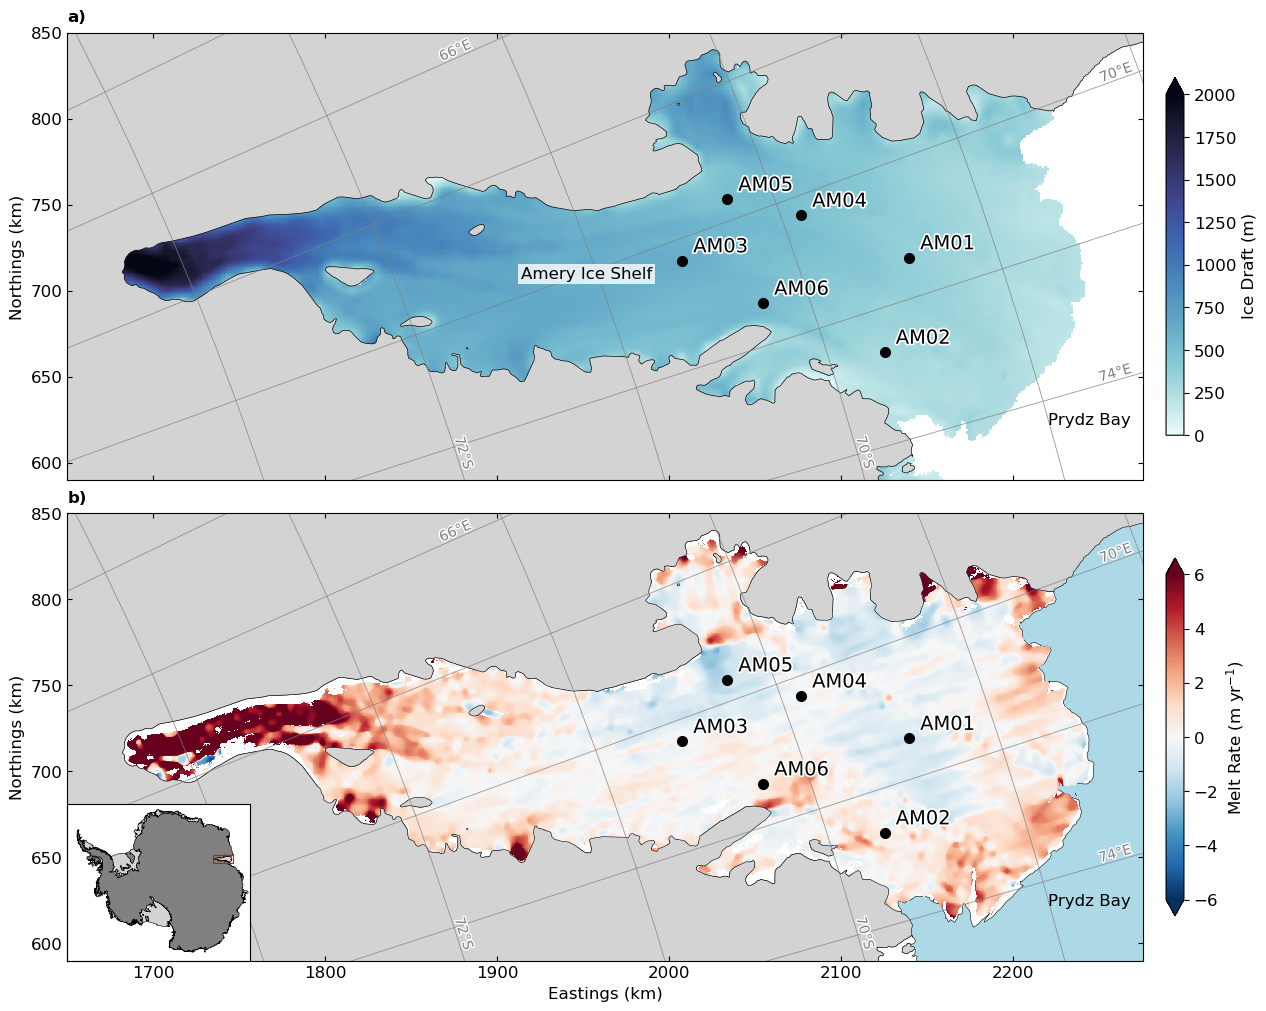

In [8]:
plt.cla()
plt.clf()

plt.rcParams['font.size'] = 12

fig, (ax_t, ax) = plt.subplots(2, 1, figsize=(13, 10), sharex=True, layout='constrained')

scale_ticks = 1e3
ticks_x = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))
ticks_y = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))

# ---------- Top Plot: Ice Thickness ----------
# Bedmap2 uses a large negative fill value for missing data, mask this
thickness_masked = thickness.where(thickness != thickness.rio.nodata).rio.clip_box(minx=1.6e6, miny=0.55e6, maxx=2.35e6, maxy=0.9e6)
surface_masked = surface.where(surface != surface.rio.nodata).rio.clip_box(minx=1.6e6, miny=0.55e6, maxx=2.35e6, maxy=0.9e6)
draft = -(surface_masked - thickness_masked)

ax_t.set_facecolor('white')

# Plot the Bedmap2 ice thickness map
im_t = draft.plot(ax=ax_t, cmap='cmo.ice_r', vmin=0, vmax=2000, add_colorbar=False, add_labels=False, zorder=2)

# Mask out grounded ice and islands
land.plot(ax=ax_t, facecolor='lightgrey', edgecolor='none', zorder=2)

# Grounding line as outline only
grounding_line.plot(ax=ax_t, facecolor='none', edgecolor='k', lw=0.5, zorder=4)

# Plot the LIMA satellite image
# (lima.astype('uint8')).plot.imshow(ax=ax_t)

# ---------- Bottom Plot: Melt Rate ----------
ax.set_facecolor('lightblue')
float_ice.plot(ax=ax, facecolor='white', edgecolor='k', lw=0.4, zorder=2)

# Plot the Adusumilli et al. (2020) melt map
im = melt_map.plot(ax=ax, cmap="RdBu_r", vmin=-6, vmax=6, add_colorbar=False, add_labels=False, zorder=2)

land.plot(ax=ax, facecolor='lightgrey', edgecolor='k', lw=0.4, zorder=2)

# Plot the LIMA satellite image
# (lima.astype('uint8')).plot.imshow(ax=ax)

# Set the same extent and aspect on both panels
for a in (ax_t, ax):
    a.set_xlim((1.65e6, 2.275e6))
    a.set_ylim((.590e6, .85e6))
    a.set_aspect('equal', adjustable='box')

# Lat/lon graticule, transformed into EPSG:3031 and drawn as ordinary lines
graticule_kwargs = dict(color='grey', lw=0.6, alpha=0.8, zorder=5)
graticule_text_kwargs = dict(color='grey', fontsize=10, zorder=6, path_effects=[pe.withStroke(linewidth=2, foreground='white')])

for a in (ax_t, ax):
    lat_1dg.plot(ax=a, **graticule_kwargs)
    lon_2dg.plot(ax=a, **graticule_kwargs)
 
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()

# Iterate over each borehole represented in the model output
for name, info in boreholes_amisor.items():
    lon0, lat0 = info['lonlat']
    bx, by = ll_to_xy.transform(lon0, lat0) # true site -> metres
    for a in (ax_t, ax):
        a.plot(bx, by, '.', color='black', ms=14, zorder=7)
        a.annotate(name, xy=(bx, by), xytext=(8, 6), textcoords='offset points', color='black', fontsize=14, zorder=7, path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])

ax_t.text(1.99e6, 0.71e6, 'Amery Ice Shelf', color='black', ha='right', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)
ax_t.text(2.22e6, 0.625e6, 'Prydz Bay', color='black', ha='left', va='center', zorder=9)
ax.text(2.22e6, 0.625e6, 'Prydz Bay', color='black', ha='left', va='center', zorder=9)

for a in (ax_t, ax):
    a.xaxis.set_major_formatter(ticks_x)
    a.yaxis.set_major_formatter(ticks_y)
    a.tick_params(axis="both", direction="in", top=True, right=True)
    a.set_axisbelow(False)
    for spine in a.spines.values():
        spine.set_zorder(10)
    a.set_ylabel('Northings (km)')
    a.set_title('')
ax.set_xlabel('Eastings (km)')

for a, label in [(ax_t, 'a)'), (ax, 'b)')]:
    a.annotate(label, xy=(0, 1), xytext=(0, 6), xycoords='axes fraction', textcoords='offset points', fontweight='bold', va='bottom', ha='left', zorder=10)

# Ice thickness colourbar on the top panel
cbar_t = fig.colorbar(im_t, ax=ax_t, location='right', shrink=0.8, pad=0.02, extend='max')
cbar_t.set_label('Ice Draft (m)')

# Melt colourbar on the bottom panel
cbar = fig.colorbar(im, ax=ax, location='right', shrink=0.8, pad=0.02, extend='both')
cbar.set_label(r'Melt Rate (m yr$^{-1}$)')

# inset_axes places it in axes-fraction coordinates: (left, bottom, width, height)
ax_inset = ax.inset_axes([0.0, 0.0, 0.17, 0.35])

ax_inset.set_facecolor('white') 
float_ice.plot(ax=ax_inset, facecolor='lightgrey', edgecolor='k', lw=0.4, zorder=2)
land.plot(ax=ax_inset, facecolor='grey', edgecolor='k', lw=0.4, zorder=2)

# Red box marking the extent of the main map
# Rectangle takes (lower-left x, lower-left y), width, height - all in EPSG:3031 metres
ax_inset.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='red', lw=0.8, zorder=5))

ax_inset.set_facecolor('white')
ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_aspect('equal')
# Pad the view a little beyond the continent so nothing is clipped
ax_inset.set_xlim(-2.8e6, 2.8e6)
ax_inset.set_ylim(-2.4e6, 2.4e6)

fig.canvas.draw()

# >>> CHANGED: per-label offset, in km back from where the line leaves the plot.
# >>> Omit a line to leave it unlabelled.
LABEL_OFFSET = {
    '66°E': 35,
    '70°E': 15,
    '74°E': 15,
    '70°S': 15,
    '72°S': 15,
}

for gdf, col, by_y in [(lon_2dg, 'Longitude', True), (lat_1dg, 'Latitude', False)]:
    for _, row in gdf.iterrows():
        if row[col] not in LABEL_OFFSET:
            continue
        parts = row.geometry.geoms if row.geometry.geom_type.startswith('Multi') else [row.geometry]
        for part in parts:
            # >>> NEW: resample to a vertex every 1 km, so the offset is in km and the angle is local
            gx, gy = np.asarray(part.segmentize(1000).coords).T
            inside = (gx > x0) & (gx < x1) & (gy > y0) & (gy < y1)
            if not inside.any():
                continue
            idx = np.flatnonzero(inside)
            # Vertex where the line leaves the view: top edge for meridians, right edge for parallels
            k = idx[np.argmax(gy[idx] if by_y else gx[idx])]
            # Step back along the line, towards the interior, by this label's offset
            step = -1 if (k > 0 and inside[k-1]) else 1
            k = k + step * LABEL_OFFSET[row[col]]
            k = min(max(k, 2), len(gx) - 3)
            # Angle from the vertices 2 km either side, so it follows the local slope of the graticule
            p0, p1 = ax.transData.transform([(gx[k-2], gy[k-2]), (gx[k+2], gy[k+2])])
            angle = np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]))
            if angle > 90: angle -= 180
            if angle < -90: angle += 180
            for a in (ax_t, ax):
                a.text(gx[k], gy[k], row[col], ha='center', va='bottom', rotation=angle, rotation_mode='anchor', **graticule_text_kwargs)
            break

fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/Amery_Map.jpg', format='jpg', dpi=300)

## Plot Prydz Bay Map

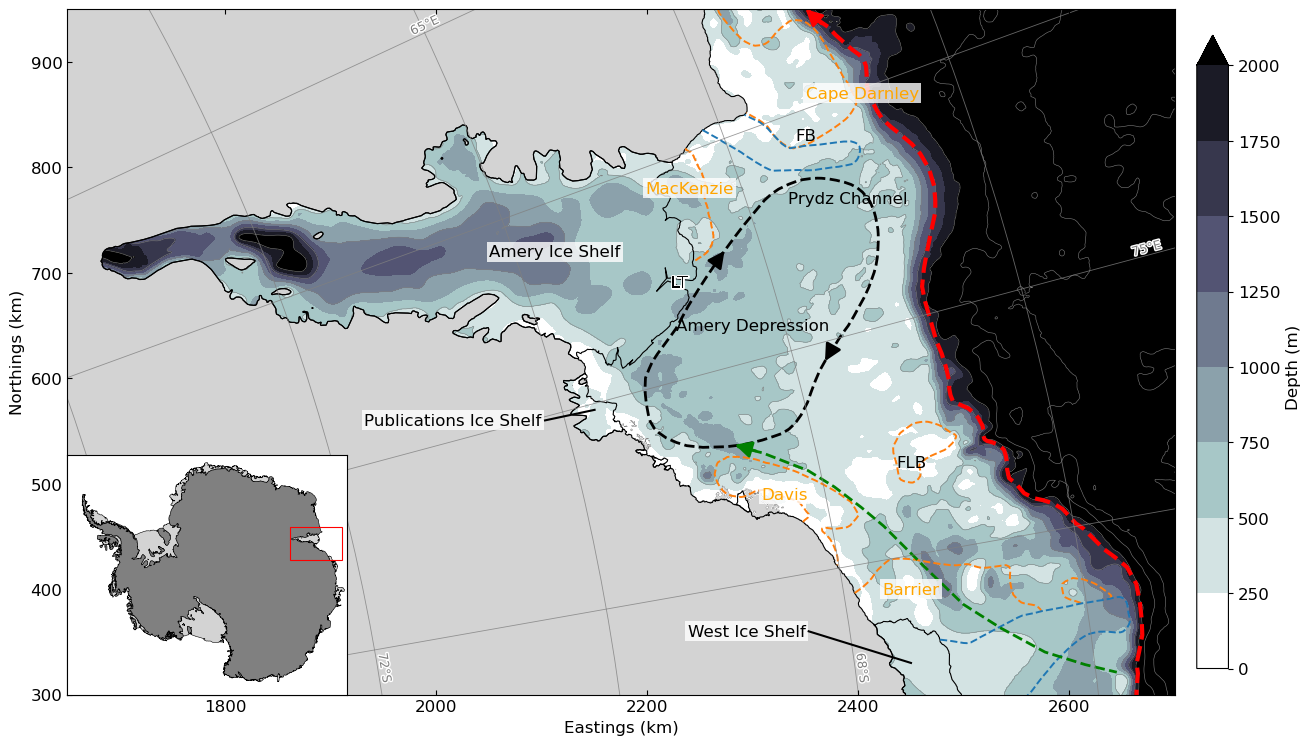

In [9]:
fig, ax = plt.subplots(figsize=(13, 8), layout='constrained')

scale_ticks = 1e3
ticks_x = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))
ticks_y = mticker.FuncFormatter(lambda x, pos: '{0:g}'.format(x/scale_ticks))

# Extent covering Prydz Bay, the Amery and the shelf break
X0, X1 = 1.65e6, 2.70e6
Y0, Y1 = 0.30e6, 0.95e6

# ---------- BATHYMETRY ----------
bed_masked = bed.where(bed != bed.rio.nodata).rio.clip_box(minx=X0-5e4, miny=Y0-5e4, maxx=X1+5e4, maxy=Y1+5e4)
depth = -bed_masked

ax.set_facecolor('lightgrey')

# Filled depth bands, matching the stepped colourbar in the reference figure
fill_levels = np.arange(0, 2001, 250)
im = depth.plot.contourf(ax=ax, cmap='bone_r', levels=fill_levels, extend='max', add_colorbar=False, add_labels=False, zorder=2)

line_levels = np.arange(0, 6001, 500)
ax.contour(depth.x, depth.y, depth, levels=line_levels, colors='grey', linewidths=0.4, zorder=3)

# ---------- LAND AND ICE ----------
land.plot(ax=ax, facecolor='lightgrey', edgecolor='none', zorder=4)

# Floating ice drawn over the bathymetry, with the cavity depth still visible beneath
float_ice.plot(ax=ax, facecolor='none', edgecolor='black', lw=0.8, zorder=5)
grounding_line.plot(ax=ax, facecolor='none', edgecolor='k', lw=0.8, zorder=5)

# ---------- PRYDZ BAY FEATURES ----------
# Polynyas and fast ice from Portela et al. (2021)
polynyas.plot(ax=ax, facecolor='none', edgecolor='tab:orange', lw=1.4, linestyle='--', zorder=6)
fast_ice.plot(ax=ax, facecolor='none', edgecolor='tab:blue', lw=1.4, linestyle='--', zorder=6)

# Prydz Bay Gyre
pbg.plot(ax=ax, facecolor='none', edgecolor='k', lw=2.0, linestyle='--', zorder=6)
for _, row in pbg.iterrows():
    geom = row.geometry
    # Polygon outlines live on .exterior; LineStrings have .coords directly
    coords = np.asarray(geom.exterior.coords if geom.geom_type == 'Polygon' else geom.coords)
    n = len(coords)
    # Place arrows at these fractions along the loop - adjust or add more
    for frac in (0, 0.5):
        k = int(frac * n)
        tail = coords[k]
        head = coords[(k + max(1, n // 50)) % n]
        ax.annotate('', xy=head, xytext=tail, arrowprops=dict(arrowstyle='-|>', color='k', lw=2.0, mutation_scale=25), zorder=7)

# Antarctic Slope Current
asc.plot(ax=ax, facecolor='none', edgecolor='red', lw=3.0, linestyle='--', zorder=6)
ax.annotate('', xy=(2.35e6, 0.95e6), xytext=(2.365e6, 0.936e6), arrowprops=dict(arrowstyle='-|>', color='red', lw=2.0, mutation_scale=25, shrinkA=0, shrinkB=0), zorder=7)

# Prydz Bay Eastern Coastal Current
pbecc.plot(ax=ax, facecolor='none', edgecolor='green', lw=2.0, linestyle='--', zorder=6)
ax.annotate('', xy=(2.283e6, 0.537e6), xytext=(2.303e6, 0.531e6), arrowprops=dict(arrowstyle='-|>', color='green', lw=2.0, mutation_scale=25, shrinkA=0, shrinkB=0), zorder=7)
    
ax.set_xlim(X0, X1)
ax.set_ylim(Y0, Y1)
ax.set_aspect('equal', adjustable='box')

# ---------- GRATICULE ----------
graticule_kwargs = dict(color='grey', lw=0.6, alpha=0.8, zorder=7)
graticule_text_kwargs = dict(color='grey', fontsize=9, zorder=8, path_effects=[pe.withStroke(linewidth=2, foreground='white')])

lat_2dg.plot(ax=ax, **graticule_kwargs)
lon_5dg.plot(ax=ax, **graticule_kwargs)

x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()

# ---------- PLACE NAMES ----------
# Ice shelves
ax.text(2.05e6, 0.72e6, 'Amery Ice Shelf', color='black', ha='left', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)
ax.text(2.10e6, 0.56e6, 'Publications Ice Shelf', color='black', ha='right', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)
ax.plot([2.103e6, 2.15e6], [0.56e6, 0.57e6], color='black', lw=1.5, zorder=9)
ax.text(2.35e6, 0.36e6, 'West Ice Shelf', color='black', ha='right', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)
ax.plot([2.353e6, 2.45e6], [0.36e6, 0.33e6], color='black', lw=1.5, zorder=9)

# Topographical features
ax.text(2.35e6, 0.83e6, 'FB', color='black', ha='center', va='center', zorder=9)
ax.text(2.45e6, 0.52e6, 'FLB', color='black', ha='center', va='center', zorder=9)
ax.text(2.30e6, 0.65e6, 'Amery Depression', color='black', ha='center', va='center', zorder=9)
ax.text(2.39e6, 0.77e6, 'Prydz Channel', color='black', ha='center', va='center', zorder=9)

ax.text(2.230e6, 0.69e6, 'LT', color='black', ha='center', va='center', path_effects=[pe.withStroke(linewidth=2, foreground='white')], zorder=9)

# Polynyas
ax.text(2.35e6, 0.87e6, 'Cape Darnley', color='orange', ha='left', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)
ax.text(2.24e6, 0.78e6, 'MacKenzie', color='orange', ha='center', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)
ax.text(2.33e6, 0.49e6, 'Davis', color='orange', ha='center', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)
ax.text(2.45e6, 0.40e6, 'Barrier', color='orange', ha='center', va='center', bbox=dict(boxstyle='square,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8), zorder=9)

ax.xaxis.set_major_formatter(ticks_x)
ax.yaxis.set_major_formatter(ticks_y)
ax.tick_params(axis="both", direction="in", top=True, right=True)
ax.set_axisbelow(False)
ax.xaxis.set_zorder(10)
ax.yaxis.set_zorder(10)
for spine in ax.spines.values():
    spine.set_zorder(10)
ax.set_xlabel('Eastings (km)')
ax.set_ylabel('Northings (km)')
ax.set_title('')

# ---------- COLOURBAR ----------
cbar = fig.colorbar(im, ax=ax, location='right', shrink=0.8, pad=0.02, extend='max')
cbar.set_label('Depth (m)')
cbar.set_ticks(fill_levels)

# ---------- LOCATOR INSET ----------
# inset_axes places it in axes-fraction coordinates: (left, bottom, width, height)
ax_inset = ax.inset_axes([0.0, 0.0, 0.253, 0.35], zorder=20)

ax_inset.set_facecolor('white')
float_ice.plot(ax=ax_inset, facecolor='lightgrey', edgecolor='k', lw=0.4, zorder=2)
land.plot(ax=ax_inset, facecolor='grey', edgecolor='k', lw=0.4, zorder=2)

# Red box marking the extent of the main map
# Rectangle takes (lower-left x, lower-left y), width, height - all in EPSG:3031 metres
ax_inset.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='red', lw=0.8, zorder=5))

ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax_inset.set_aspect('equal')
# Pad the view a little beyond the continent so nothing is clipped
ax_inset.set_xlim(-2.8e6, 2.8e6)
ax_inset.set_ylim(-2.4e6, 2.4e6)

fig.canvas.draw()

# ---------- GRATICULE LABELS ----------
# Per-label offset, in km back from where the line leaves the plot.
# Omit a line to leave it unlabelled.
LABEL_OFFSET = {
    '65°E': 50,
    '75°E': 25,
    '68°S': 25,
    '72°S': 25
}

for gdf, col, by_y in [(lon_5dg, 'Longitude', True), (lat_2dg, 'Latitude', False)]:
    for _, row in gdf.iterrows():
        if row[col] not in LABEL_OFFSET:
            continue
        parts = row.geometry.geoms if row.geometry.geom_type.startswith('Multi') else [row.geometry]
        for part in parts:
            # Resample to a vertex every 1 km, so the offset is in km and the angle is local
            gx, gy = np.asarray(part.segmentize(1000).coords).T
            inside = (gx > x0) & (gx < x1) & (gy > y0) & (gy < y1)
            if not inside.any():
                continue
            idx = np.flatnonzero(inside)
            # Vertex where the line leaves the view: top edge for meridians, right edge for parallels
            k = idx[np.argmax(gy[idx] if by_y else gx[idx])]
            # Step back along the line, towards the interior, by this label's offset
            step = -1 if (k > 0 and inside[k-1]) else 1
            k = k + step * LABEL_OFFSET[row[col]]
            k = min(max(k, 2), len(gx) - 3)
            # Angle from the vertices either side, so it follows the local slope of the graticule
            p0, p1 = ax.transData.transform([(gx[k-2], gy[k-2]), (gx[k+2], gy[k+2])])
            angle = np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]))
            if angle > 90: angle -= 180
            if angle < -90: angle += 180
            ax.text(gx[k], gy[k], row[col], ha='center', va='bottom', rotation=angle,
                    rotation_mode='anchor', **graticule_text_kwargs)
            break

fig.savefig('/g/data/gv90/ad6790/amery-amisor/notebooks/figures/Prydz_Bay_Map.jpg', format='jpg', dpi=300)